# Layered water: progressively weaker damping

RuO2/TiO2 at 20 keV, with water following the same smooth Poisson surface as
the other DWBA example. Only **cumulative broadening** changes:
$\sigma_j^2=\sigma_0^2+j\sigma_{\mathrm{bar}}^2$, where $j=0,1,\ldots$.
Reducing $\sigma_{\mathrm{bar}}$ makes water-density oscillations persist farther
from the surface; it does not change absorption, occupancy or crystallinity.

We use **$d=2.8$ Angstrom**: 3D-AFM measurements report an approximately
0.28 nm hydration-layer separation on mica in
[Angstrom-Scale Water Layer Structure on van der Waals Materials Probed by
3D Atomic Force Microscopy: From Acidic to Alkaline Aqueous Solutions,
Langmuir, DOI 10.1021/acs.langmuir.5c05798](https://doi.org/10.1021/acs.langmuir.5c05798).
This is a literature-motivated molecular-layer spacing, **not a RuO2-specific
measurement or a metal-water bond length**. The illustrative first-layer
center remains 3.0 Angstrom above each terrace; its intrinsic width is fixed
at 0.60 Angstrom and relative weight at A0=0.8. The width and damping sweep
are illustrative parameters, not values fitted in that publication.

For intuition, the broadening of successive Gaussians gives an intrinsic
amplitude factor $\exp(-q_z^2\sigma_{\mathrm{bar}}^2/2)$ per layer. At
$q_z=2\pi/d$, that factor increases as damping decreases. This is an amplitude
factor, not an intensity attenuation coefficient. Every case keeps positive
`sigma_bar`, so the density ultimately reaches homogeneous bulk water.


In [1]:
from pathlib import Path
import copy
import sys
import time
import numpy as np
import matplotlib.pyplot as plt

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "orgui").is_dir())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from examples.CTR.water_models_example import create_example
from orgui.datautils.xrayutils.CTRuc import WaterModel
from orgui.datautils.xrayutils.CTRfilm import PoissonSurface

base = create_example("layered")
base.apply_stacking()
surface = next(c for c in base.uc_surface_list if isinstance(c, PoissonSurface))
heights, probabilities, _ = surface.terrace_distribution()
mean_height = heights @ probabilities
cell = base.uc_bulk
height = cell.volume / cell.uc_area  # normal cell height, Angstrom
spacing, onset, sigma0, A0 = 2.8, 3.0, 0.60, 0.8
broadenings = [1.4, 1.0, 0.65, 0.40]  # Angstrom: progressively less damping
colors = plt.cm.Blues(np.linspace(0.40, 0.95, len(broadenings)))
styles = [":", "--", "-.", "-"]
models, intrinsic = {}, {}
for sigma_bar in broadenings:
    water = WaterModel(cell.a.copy(), np.rad2deg(cell.alpha), "layered",
                       optical_reference="sharp", name="layered_water")
    water.setWaterParameters(onset/height, spacing/height, sigma0/height,
                             sigma_bar/height, A0)
    water.setEnergy(base.uc_bulk._E)
    intrinsic[sigma_bar] = water
    model = copy.deepcopy(base)
    next(c for c in model.uc_surface_list if isinstance(c, PoissonSurface)).attach_water(copy.deepcopy(water))
    models[sigma_bar] = model
    np.testing.assert_allclose(water.basis[:4]*height, [onset, spacing, sigma0, sigma_bar])
    # Check well inside bulk water; transition_extent is a tail estimate.
    tail = water.transition_extent(tolerance=1e-12)[1] + 8*spacing
    np.testing.assert_allclose(water.zDensity_G(tail + np.arange(1., 6.), 0., 0.), water.bulk_density,
                               rtol=1e-8, atol=1e-11)
    factor = np.exp(-0.5*(2*np.pi/spacing)**2*sigma_bar**2)
    print(f"sigma_bar={sigma_bar:.2f} A: intrinsic amplitude factor per layer at qz=2pi/d = {factor:.3f}")


sigma_bar=1.40 A: intrinsic amplitude factor per layer at qz=2pi/d = 0.007
sigma_bar=1.00 A: intrinsic amplitude factor per layer at qz=2pi/d = 0.081
sigma_bar=0.65 A: intrinsic amplitude factor per layer at qz=2pi/d = 0.345
sigma_bar=0.40 A: intrinsic amplitude factor per layer at qz=2pi/d = 0.668


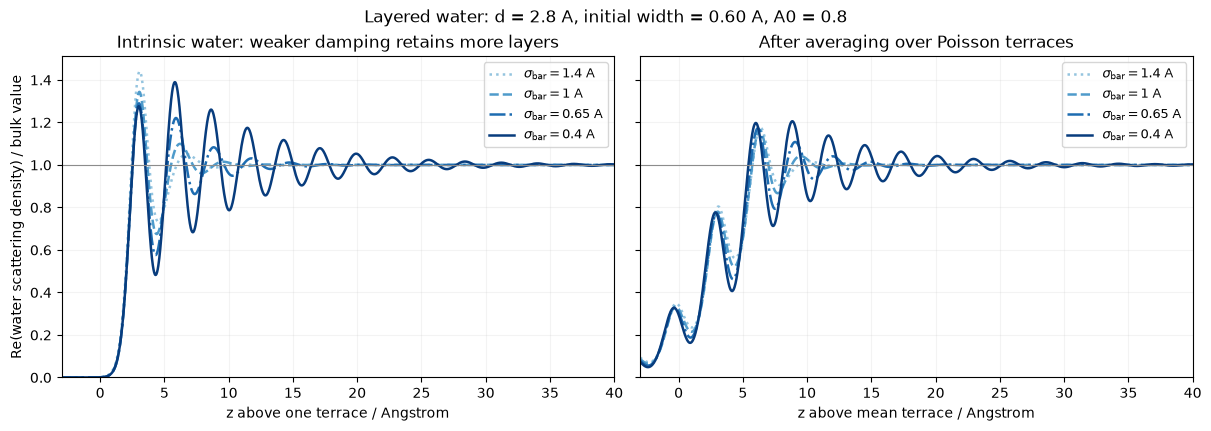

In [2]:
z = np.linspace(-3., 40., 1721)
fig_density, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True, constrained_layout=True)
for sigma_bar, color, style in zip(broadenings, colors, styles):
    water = intrinsic[sigma_bar]
    flat = water.zDensity_G(z, 0., 0.).real / water.bulk_density.real
    averaged = sum(p*water.zDensity_G(z + mean_height - h, 0., 0.).real
                   for h, p in zip(heights, probabilities)) / water.bulk_density.real
    label = rf"$\sigma_{{\rm bar}}={sigma_bar:g}$ A"
    axes[0].plot(z, flat, color=color, ls=style, lw=1.8, label=label)
    axes[1].plot(z, averaged, color=color, ls=style, lw=1.8, label=label)
for ax in axes:
    ax.axhline(1., color="0.55", lw=.8)
    ax.set(xlim=(-3, 40), ylim=(0, None), xlabel="z above local / mean terrace plane / Angstrom")
    ax.grid(alpha=.15)
    ax.legend(fontsize=9)
axes[0].set(title="Intrinsic water: weaker damping retains more layers",
            xlabel="z above one terrace / Angstrom", ylabel="Re(water scattering density) / bulk value")
axes[1].set(title="After averaging over Poisson terraces", xlabel="z above mean terrace / Angstrom")
fig_density.suptitle("Layered water: d = 2.8 A, initial width = 0.60 A, A0 = 0.8")
plt.show()


## Specular CTR / reflectivity through L = 3

Layered water uses a sharp equimolar optical reference plus its analytic infinite
Hosemann contrast in DWBA. Each model is prepared afresh, including its changed
equimolar plane. Curves are compared at **one common plane in bulk water**,
with equal local incident/exit angles and s polarization. The ratio panel
uses the most strongly damped case as the baseline, without independently
rescaling curves. The dashed vertical line marks $q_z=2\pi/d$, where persistent
water layering can enhance its scattering; interference with the solid also
affects the observed CTR. The infinite stack is evaluated in closed form; weaker damping
adds no molecular-layer enumeration or integration work.


sigma_bar=1.40 A: 180 DWBA points in 0.44 s
sigma_bar=1.00 A: 180 DWBA points in 0.18 s


sigma_bar=0.65 A: 180 DWBA points in 0.19 s
sigma_bar=0.40 A: 180 DWBA points in 0.17 s


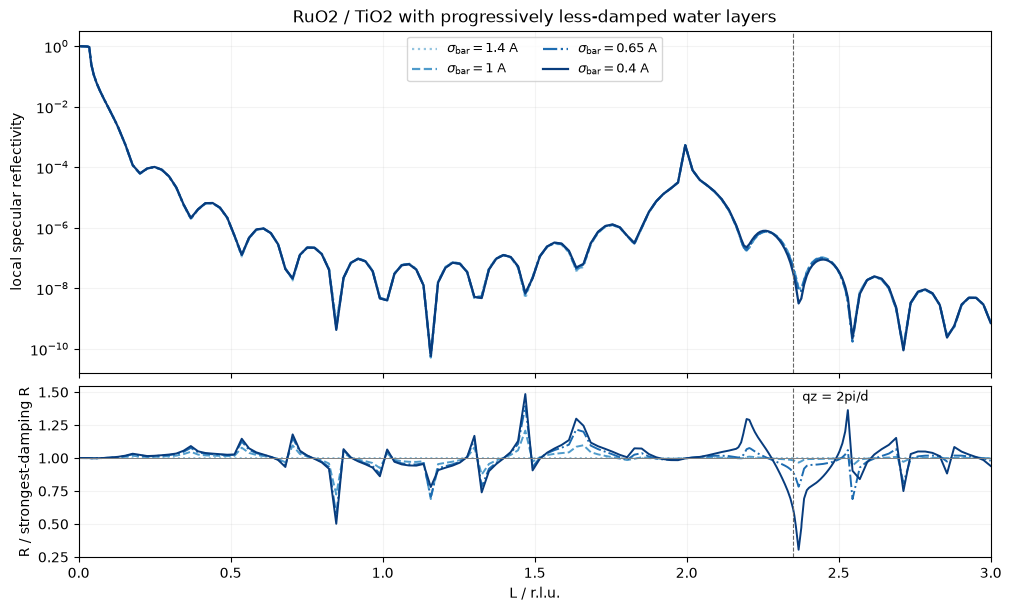

In [3]:
layer_L = height / spacing
L = np.unique(np.r_[np.geomspace(.006, .12, 18), np.linspace(.13, 3., 121),
                     np.linspace(layer_L-.18, layer_L+.18, 41)])
results = {}
for sigma_bar, model in models.items():
    model.dwba.set_ctr_geometry(equal_angles=True, rods=[(0., 0.)])
    start = time.perf_counter()
    results[sigma_bar] = model.dwba.evaluate(np.zeros_like(L), np.zeros_like(L), L)
    assert np.isfinite(results[sigma_bar].total_amplitude).all()
    water = next(c for c in model.uc_surface_list if isinstance(c, PoissonSurface)).water
    check_z = np.linspace(-2., 40., 101)
    expected = sum(p*intrinsic[sigma_bar].zDensity_G(check_z+mean_height-h, 0., 0.)
                   for h, p in zip(heights, probabilities))
    np.testing.assert_allclose(water.zDensity_G(check_z+mean_height, 0., 0.), expected, rtol=1e-12, atol=1e-12)
    print(f"sigma_bar={sigma_bar:.2f} A: {len(L)} DWBA points in {time.perf_counter()-start:.2f} s")
common_plane = max(next(c for c in m.uc_surface_list if isinstance(c, PoissonSurface))
                   .water.transition_extent()[1] for m in models.values()) + 8.
reflectivity = {}
for sigma_bar, result in results.items():
    p = result.prepared
    origin = float(np.atleast_1d(p.field_i.z_reference)[0])
    phase = np.exp(-1j*p.k0*p.reference.n[0]*(np.sin(p.alpha_i)+np.sin(p.alpha_f))*(common_plane-origin))
    reflectivity[sigma_bar] = abs(result.total_amplitude*phase)**2
fig_ctr, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]}, constrained_layout=True)
baseline = reflectivity[broadenings[0]]
for sigma_bar, color, style in zip(broadenings, colors, styles):
    label = rf"$\sigma_{{\rm bar}}={sigma_bar:g}$ A"
    axes[0].semilogy(L, reflectivity[sigma_bar], color=color, ls=style, lw=1.6, label=label)
    axes[1].plot(L, reflectivity[sigma_bar]/baseline, color=color, ls=style, lw=1.4)
for ax in axes:
    ax.axvline(layer_L, color="0.4", ls="--", lw=.8)
    ax.grid(alpha=.15)
axes[0].set(ylabel="local specular reflectivity", title="RuO2 / TiO2 with progressively less-damped water layers")
axes[0].legend(fontsize=9, ncol=2)
axes[1].axhline(1., color="0.5", lw=.7)
axes[1].set(xlim=(0., 3.), xlabel="L / r.l.u.", ylabel="R / strongest-damping R")
axes[1].text(layer_L+.03, .98, "qz = 2pi/d", transform=axes[1].get_xaxis_transform(), va="top", fontsize=9)
plt.show()

# Optional export of any complete model:
# models[0.40].toFile(root / "examples/CTR/layered_water_low_damping.xtal")


## Full CTRs and the water-only signal

The first three panels show the **full coherent DWBA result**, including the
optical reference, solid perturbation and water perturbation:
$F_{\rm effective}=(r_0+\delta r_{\rm solid}+\delta r_{\rm water})/C$,
where $C$ is the DWBA amplitude prefactor. All curves use the same observation
plane in bulk water, with no independent intensity rescaling.

The fourth panel makes the **complete water density's Fourier signal** visible
separately: $|F_{\rm water}^{\rm kin}|^2$, including the half-space onset,
layering, molecular form factor and terrace averaging. This is a kinematic
component diagnostic, not a standalone DWBA reflectivity or just the
water-minus-reference perturbation. Component intensities must not be added:
the full calculation adds complex amplitudes before squaring.

The water has no lateral order, so its direct contribution to $01L$ and $11L$
is zero. Their water dependence comes through the optical fields; overlapping
curves are expected. The vertical line on $00L$ marks $q_z=2\pi/d$.

Completed 00L for all four water damping values


Completed 01L for all four water damping values


Completed 11L for all four water damping values


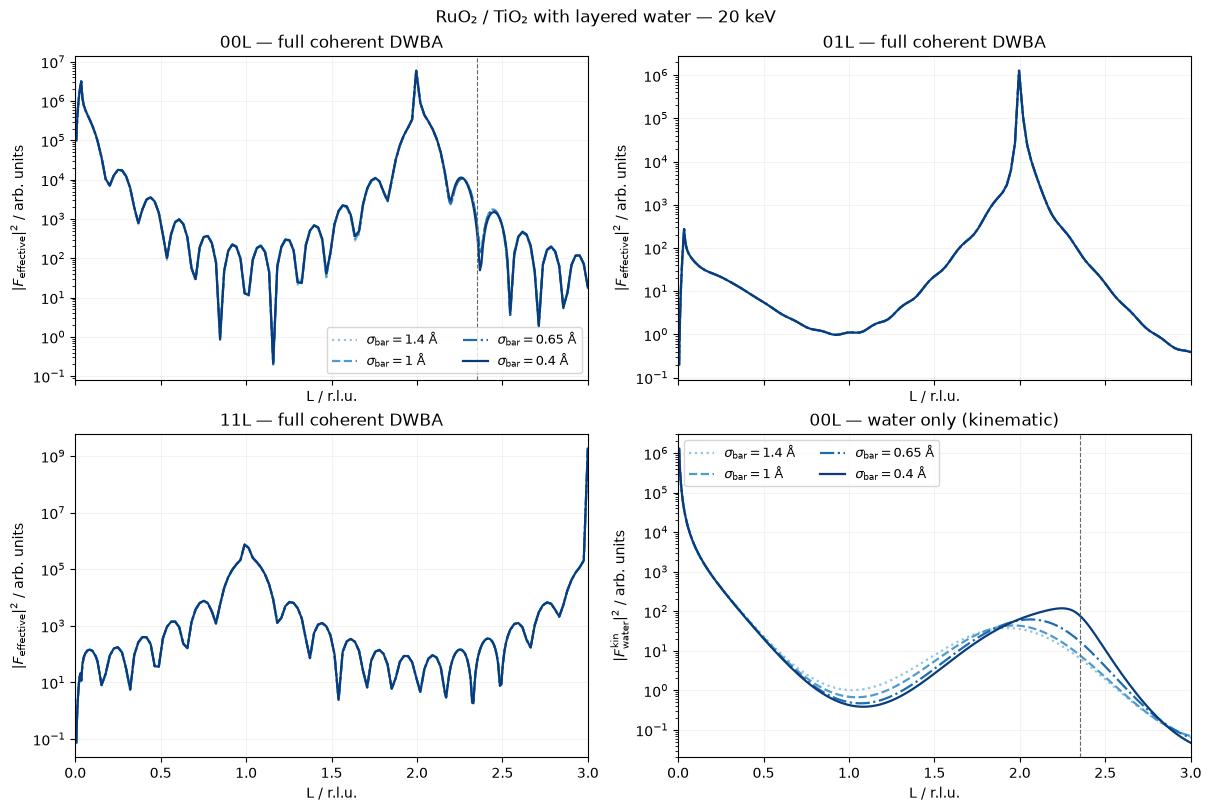

In [4]:
rods = [(0, 0), (0, 1), (1, 1)]
ctr_results = {}
fig_full, full_axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True,
                                  constrained_layout=True)
for ax, (h, k) in zip(full_axes.flat, rods):
    for sigma_bar, color, style in zip(broadenings, colors, styles):
        model = models[sigma_bar]
        if (h, k) == (0, 0):
            result = results[sigma_bar]
        else:
            model.dwba.set_ctr_geometry(equal_angles=True, rods=[(h, k)])
            result = model.dwba.evaluate(np.full_like(L, h), np.full_like(L, k), L)
        ctr_results[h, k, sigma_bar] = result
        water_terms = [c.F_h for c in result.contributions if c.role == "water"]
        assert water_terms
        if (h, k) != (0, 0):
            np.testing.assert_allclose(water_terms, 0., atol=1e-12)
        np.testing.assert_allclose(sum(c.F_h for c in result.contributions),
                                   result.F_h, rtol=1e-10, atol=1e-10)
        p = result.prepared
        origin = float(np.atleast_1d(p.field_i.z_reference)[0])
        phase = np.exp(-1j*p.k0*p.reference.n[0]*(np.sin(p.alpha_i)+np.sin(p.alpha_f))
                       *(common_plane-origin))
        intensity = abs(result.F_effective*phase)**2
        assert np.isfinite(intensity).all()
        label = rf"$\sigma_{{\rm bar}}={sigma_bar:g}$ Å"
        ax.semilogy(L, intensity, color=color, ls=style, lw=1.6, label=label)
    ax.set(title=f"{h}{k}L — full coherent DWBA",
           ylabel=r"$|F_{\rm effective}|^2$ / arb. units")
    print(f"Completed {h}{k}L for all four water damping values")

ax_water = full_axes[1, 1]
for sigma_bar, color, style in zip(broadenings, colors, styles):
    water = next(c for c in models[sigma_bar].uc_surface_list
                 if isinstance(c, PoissonSurface)).water
    F_water = water.F_uc(np.zeros_like(L), np.zeros_like(L), L)
    assert np.isfinite(F_water).all()
    label = rf"$\sigma_{{\rm bar}}={sigma_bar:g}$ Å"
    ax_water.semilogy(L, abs(F_water)**2, color=color, ls=style, lw=1.6, label=label)
ax_water.set(title="00L — water only (kinematic)",
             ylabel=r"$|F_{\rm water}^{\rm kin}|^2$ / arb. units")
for ax in (full_axes[0, 0], ax_water):
    ax.axvline(layer_L, color="0.4", ls="--", lw=.8)
for ax in full_axes.flat:
    ax.set(xlim=(0., 3.), xlabel="L / r.l.u.")
    ax.grid(alpha=.15)
full_axes[0, 0].legend(fontsize=9, ncol=2)
ax_water.legend(fontsize=9, ncol=2)
fig_full.suptitle("RuO₂ / TiO₂ with layered water — 20 keV")
plt.show()
